<a href="https://colab.research.google.com/github/Sayak-coder/HateSpeech-detection/blob/main/StereoQueerEval_EN(bidirectional_LSTM).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd

In [14]:
df = pd.read_csv('/content/StereoQueerEval_EN_training.tsv',sep='\t')
df.head()

,StereoQueerEval_id,yt_title,yt_description,yt_comment,stereotype,hate_speech,target
0,training_EN_0001,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes,yes_explicit,individual_l
1,training_EN_0002,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes,yes_implicit,group_t
2,training_EN_0003,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes,yes_implicit,"group_l,g"
3,training_EN_0004,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes,yes_implicit,group_l
4,training_EN_0005,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes,yes_implicit,group_g


In [15]:
df = df.drop(['hate_speech', 'target','StereoQueerEval_id'], axis=1)
df.head()

,yt_title,yt_description,yt_comment,stereotype
0,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes
1,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes
2,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes
3,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes
4,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes


In [16]:
df['stereotype']=df['stereotype'].map({'no':0, 'yes':1})
df.head()

,yt_title,yt_description,yt_comment,stereotype
0,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,1
1,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,1
2,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",1
3,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,1
4,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,1


In [17]:
df.isna().sum()

,0
yt_title,0
yt_description,0
yt_comment,0
stereotype,0


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dense
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [19]:
X = df.drop('stereotype',axis=1)
y = df['stereotype']

In [20]:
X

,yt_title,yt_description,yt_comment
0,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...
1,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...
2,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall..."
3,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...
4,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him
...,...,...,...
2984,Lesbian magazine Curve 'saved people from lone...,A new documentary called Ahead of the Curve ch...,Somewhere in germany Kolon some guy has taken ...
2985,TURKEY: RIOT POLICE BREAK UP GAY PRIDE PARADE,"To License This Clip, Click Here: [URL]",Respect from Uzbekistan
2986,Argentina’s transgender soccer star,"Meet Mara Gomez, Argentina’s first transgender...",Yeah.. super fair to all those REAL women.
2987,Model comes out as intersex,Model Hanne Gaby Odiele has revealed that she ...,Good for her. Everyone has the right to be wan...


In [21]:
y

,stereotype
0,1
1,1
2,1
3,1
4,1
...,...
2984,0
2985,0
2986,1
2987,0


In [22]:
import nltk
import re
from nltk.corpus import stopwords

In [23]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

#Using different corpus for different column

In [24]:
from nltk.stem.porter import PorterStemmer

stemmer = PorterStemmer()
corpus_title = []
corpus_description = []
corpus_comment = []

# Process yt_title
for text in X['yt_title']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_title.append(review)

# Process yt_description
for text in X['yt_description']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_description.append(review)

# Process yt_comment
for text in X['yt_comment']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_comment.append(review)

In [25]:
voc_size = 5000

one_hot_rep_comment=[one_hot(word,voc_size)for word in corpus_comment]
one_hot_rep_description=[one_hot(word,voc_size)for word in corpus_description]
one_hot_rep_title=[one_hot(word,voc_size)for word in corpus_title]

In [31]:
print(corpus_comment[10])
print(one_hot_rep_comment[10])

win like everi politician lie give vagu answer
[2057, 2705, 1111, 364, 2367, 388, 81, 2144]


In [27]:
max_length=30

embedded_doc_comment=pad_sequences(one_hot_rep_comment,padding='post',maxlen=max_length)
embedded_doc_description=pad_sequences(one_hot_rep_description,padding='post',maxlen=max_length)
embedded_doc_title=pad_sequences(one_hot_rep_title,padding='post',maxlen=max_length)

In [28]:
print(embedded_doc_title)
print(embedded_doc_description)
print(embedded_doc_comment)

[[2237 1637  868 ...    0    0    0]
 [2037 1111 4533 ...    0    0    0]
 [2596 1314 3432 ...    0    0    0]
 ...
 [3910 2068 4895 ...    0    0    0]
 [ 858 3314 3911 ...    0    0    0]
 [4532 1493 2360 ...    0    0    0]]
[[2237  249 1888 ...    0    0    0]
 [ 441 1754 4533 ... 1148 2237  228]
 [2596 1314 1461 ...    0    0    0]
 ...
 [2237 2590  755 ... 2237 4340 1046]
 [ 858 3559 3167 ...    0    0    0]
 [3942 4842 4532 ...    0    0    0]]
[[3901 2943 4197 ...    0    0    0]
 [1430 3516 4265 ...    0    0    0]
 [1076 3273 2519 ...    0    0    0]
 ...
 [3887 3809  231 ...    0    0    0]
 [3469 1029 2586 ...    0    0    0]
 [ 710 1474 1111 ...    0    0    0]]


In [34]:
from tensorflow.keras.layers import Bidirectional

embedding_vector_features=40
model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(Bidirectional(LSTM(150)))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [35]:
embeded_doc = pd.DataFrame({
    'yt_title': list(embedded_doc_title),
    'yt_description': list(embedded_doc_description),
    'yt_comment': list(embedded_doc_comment)
})
display(embeded_doc.head())

,yt_title,yt_description,yt_comment
0,"[2237, 1637, 868, 770, 577, 0, 0, 0, 0, 0, 0, ...","[2237, 249, 1888, 741, 2911, 1338, 868, 770, 2...","[3901, 2943, 4197, 2344, 3655, 2836, 0, 0, 0, ..."
1,"[2037, 1111, 4533, 3207, 2861, 472, 4310, 113,...","[441, 1754, 4533, 3207, 2068, 472, 651, 649, 7...","[1430, 3516, 4265, 4816, 2919, 3282, 3132, 856..."
2,"[2596, 1314, 3432, 3129, 3318, 0, 0, 0, 0, 0, ...","[2596, 1314, 1461, 3129, 2586, 3432, 3318, 439...","[1076, 3273, 2519, 4295, 4431, 574, 4402, 2344..."
3,"[3760, 98, 1355, 3129, 2128, 1807, 0, 0, 0, 0,...","[1664, 3760, 98, 2128, 1355, 1637, 2531, 2911,...","[379, 3881, 115, 3960, 3657, 345, 2202, 4247, ..."
4,"[1177, 3240, 2068, 2189, 1779, 3129, 74, 2237,...","[2586, 3440, 3028, 2586, 2075, 3405, 2475, 218...","[4818, 3633, 1093, 4272, 0, 0, 0, 0, 0, 0, 0, ..."


In [36]:
len(embeded_doc)

2989

In [37]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=45)
train_val_idx, test_idx = next(gss_test.split(embeded_doc, y, groups=df['yt_title']))

X_train_val = embeded_doc.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
titles_train_val = df['yt_title'].iloc[train_val_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=45)
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups=titles_train_val))

X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

X_test = embeded_doc.iloc[test_idx]
y_test = y.iloc[test_idx]

In [38]:
X_train.shape,X_val.shape, X_test.shape

((1907, 3), (459, 3), (623, 3))

In [39]:
import numpy as np

X_train = np.hstack([
    np.stack(X_train['yt_title'].values),
    np.stack(X_train['yt_description'].values),
    np.stack(X_train['yt_comment'].values)
])

X_val = np.hstack([
    np.stack(X_val['yt_title'].values),
    np.stack(X_val['yt_description'].values),
    np.stack(X_val['yt_comment'].values)
])

X_test = np.hstack([
    np.stack(X_test['yt_title'].values),
    np.stack(X_test['yt_description'].values),
    np.stack(X_test['yt_comment'].values)
])

In [40]:
epochs=20
model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=epochs,batch_size=64)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 451ms/step - accuracy: 0.5669 - loss: 0.6827 - val_accuracy: 0.5948 - val_loss: 0.6751
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 358ms/step - accuracy: 0.6130 - loss: 0.6573 - val_accuracy: 0.6340 - val_loss: 0.6385
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 486ms/step - accuracy: 0.6702 - loss: 0.6020 - val_accuracy: 0.6405 - val_loss: 0.6266
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 423ms/step - accuracy: 0.6707 - loss: 0.6060 - val_accuracy: 0.5643 - val_loss: 0.6933
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 394ms/step - accuracy: 0.6665 - loss: 0.6053 - val_accuracy: 0.5708 - val_loss: 0.6873
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 357ms/step - accuracy: 0.6670 - loss: 0.5992 - val_accuracy: 0.5708 - val_loss: 0.6920
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 405ms/step - accuracy: 0.6439 - loss: 0.6042 - val_accuracy: 0.5664 - val_loss: 0.6832
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 428ms/step - accuracy: 0.6744 - loss: 0.5942 - val_accu

In [41]:
y_pred=model.predict(X_test)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step


In [42]:
import numpy as np
y_pred=np.where(y_pred>0.5,1,0)

In [43]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_pred,y_test))

0.5473515248796148


In [44]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.54      0.90      0.67       321
           1       0.62      0.17      0.27       302

    accuracy                           0.55       623
   macro avg       0.58      0.54      0.47       623
weighted avg       0.58      0.55      0.48       623



#Using dropouts


In [48]:
from tensorflow.keras.layers import Dropout, Bidirectional, LSTM, Embedding, Dense
from tensorflow.keras.models import Sequential

embedding_vector_features=40
model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(Dropout(0.3))
model.add(Bidirectional(LSTM(128, return_sequences=True)))
model.add(Dropout(0.3))
model.add(Bidirectional(LSTM(64)))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [49]:
epochs=20
model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=epochs,batch_size=64)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 680ms/step - accuracy: 0.5663 - loss: 0.6821 - val_accuracy: 0.6187 - val_loss: 0.6648
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 601ms/step - accuracy: 0.6046 - loss: 0.6658 - val_accuracy: 0.6318 - val_loss: 0.6575
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 728ms/step - accuracy: 0.6990 - loss: 0.5784 - val_accuracy: 0.6449 - val_loss: 0.6332
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 600ms/step - accuracy: 0.7729 - loss: 0.4882 - val_accuracy: 0.6928 - val_loss: 0.5972
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 604ms/step - accuracy: 0.8165 - loss: 0.4184 - val_accuracy: 0.6776 - val_loss: 0.6391
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 665ms/step - accuracy: 0.8395 - loss: 0.3809 - val_accuracy: 0.6797 - val_loss: 0.6836
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 596ms/step - accuracy: 0.8736 - loss: 0.3054 - val_accuracy: 0.6754 - val_loss: 0.7914
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 598ms/step - accuracy: 0.9088 - loss: 0.2314 - val_accu

In [50]:
y_pred=model.predict(X_test)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 208ms/step


In [51]:
import numpy as np
y_pred=np.where(y_pred>0.5,1,0)

In [52]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_pred,y_test))

0.5971107544141252


In [53]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.60      0.64      0.62       321
           1       0.59      0.56      0.57       302

    accuracy                           0.60       623
   macro avg       0.60      0.60      0.60       623
weighted avg       0.60      0.60      0.60       623



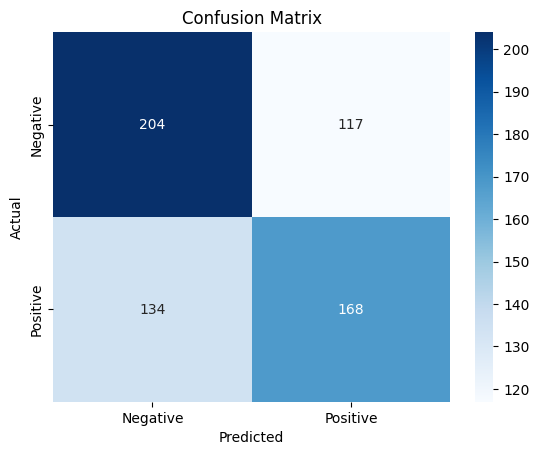

In [54]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()